In [6]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Carregando o dataset processado
df = pd.read_csv('../data/processed/dataset_preprocessed.csv')

# Definindo o Alvo (y): o tempo real de entrega em minutos
y = df['actual_delivery_time_minutes']

# Definindo as Variáveis (X): tirando o alvo e colunas do futuro (data leakage)
colunas_para_remover = [
    'actual_delivery_time_minutes',
    'estimated_delivery_time_minutes',
    'late_delivery',
    'restaurant_preparation_time_minutes'
]

X = df.select_dtypes(include=['number']).drop(columns=colunas_para_remover)
print(f"Total de características usadas agora: {X.shape[1]}")

Total de características usadas agora: 29


In [7]:
# Dividindo os dados em Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Linhas para o modelo estudar (treino): {X_train.shape[0]}")
print(f"Linhas para a prova final (teste): {X_test.shape[0]}")

# Instanciando e treinando o modelo de Regressão Linear
model_reg = LinearRegression()
model_reg.fit(X_train, y_train)

# Gerando as previsões necessárias para as próximas etapas
y_pred = model_reg.predict(X_test)

Linhas para o modelo estudar (treino): 39305
Linhas para a prova final (teste): 9827


In [8]:
# Carregar o scaler do target salvo no pré-processamento
scaler_y = joblib.load('../models/scaler_y.pkl')

# Reverter as previsões e o teste para a escala original (minutos)
y_test_minutos = scaler_y.inverse_transform(y_test.values.reshape(-1, 1))
y_pred_minutos = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

# Calcular o MAE real em minutos e R²
mae_minutos = mean_absolute_error(y_test_minutos, y_pred_minutos)
r2 = r2_score(y_test, y_pred)

print(f"Erro Médio Absoluto (MAE): {mae_minutos:.2f} minutos")
print(f"Coeficiente de Determinação (R²): {r2:.2f}")

Erro Médio Absoluto (MAE): 3.50 minutos
Coeficiente de Determinação (R²): 0.91


In [9]:
# Descobrindo o peso de cada fator no tempo de entrega
coeficientes = pd.DataFrame({
    'Variavel': X.columns,
    'Peso_Minutos': model_reg.coef_
}).sort_values(by='Peso_Minutos', ascending=False)

print("Top fatores que mais influenciam o tempo de entrega:")
print(coeficientes.head(10))

Top fatores que mais influenciam o tempo de entrega:
             Variavel  Peso_Minutos
12        distance_km      0.678294
5            subtotal      0.598110
7          tax_amount      0.224198
18      weather_Storm      0.080899
4         items_count      0.045375
17       weather_Rain      0.037037
8         service_fee      0.015485
9        delivery_fee      0.013914
16     weather_Cloudy      0.011331
3   restaurant_rating      0.003472


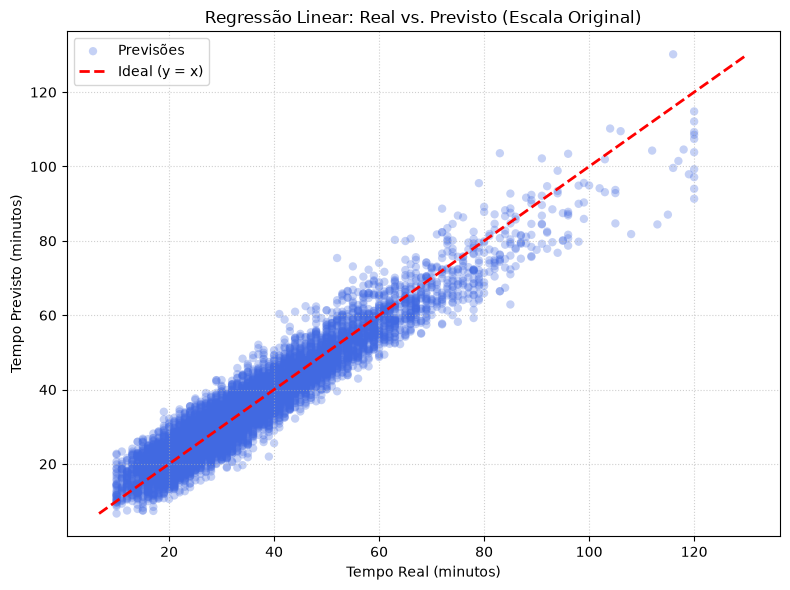

In [10]:
# Garantindo as variáveis na escala original para o gráfico
y_test_inv = y_test_minutos
y_pred_inv = y_pred_minutos

plt.figure(figsize=(8, 6))
plt.scatter(y_test_inv, y_pred_inv, alpha=0.3, color='royalblue', edgecolors='none', label='Previsões')

# Linha de referência y = x (ideal)
limites = [min(min(y_test_inv), min(y_pred_inv)), max(max(y_test_inv), max(y_pred_inv))]
plt.plot(limites, limites, color='red', linestyle='--', linewidth=2, label='Ideal (y = x)')

plt.xlabel('Tempo Real (minutos)')
plt.ylabel('Tempo Previsto (minutos)')
plt.title('Regressão Linear: Real vs. Previsto (Escala Original)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Salvando o gráfico antes de exibir
plt.savefig('../reports/figures/regression_scatter.png', dpi=300, bbox_inches='tight')

plt.show()